# 3.6 — Color palette criterion

Demonstrate `ColorPaletteCriterion` with dictionary settings and `CVInput`.

Colors are extracted using k-means in CIELAB D65. Proportions count all image pixels.
Palette distance is a weighted mean nearest Delta E 76 distance: smaller means closer,
not an automatic brand pass. The palettes below are illustrative, not approved brand colors.

This notebook demonstrates use and interpretation. 

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from PIL import Image

In [2]:
from brandlens.cv.color_palette_criterion import ColorPaletteCriterion
from brandlens.cv.cv_input import CVInput

palette = ["#000000", "#FFFFFF"]  # Illustrative palette
criterion = ColorPaletteCriterion({"n_clusters": 5, "brand_palette": palette})
print(criterion.settings)

{'n_clusters': 5, 'random_seed': 42, 'max_sample_pixels': 50000, 'brand_palette': ['#000000', '#FFFFFF']}


## Images and extracted color proportions

Bars show the whole-image proportion assigned to each representative color.
The RGB/hex display colors approximate the underlying Lab centers. Calculations use
those original centers, not the rounded display colors.

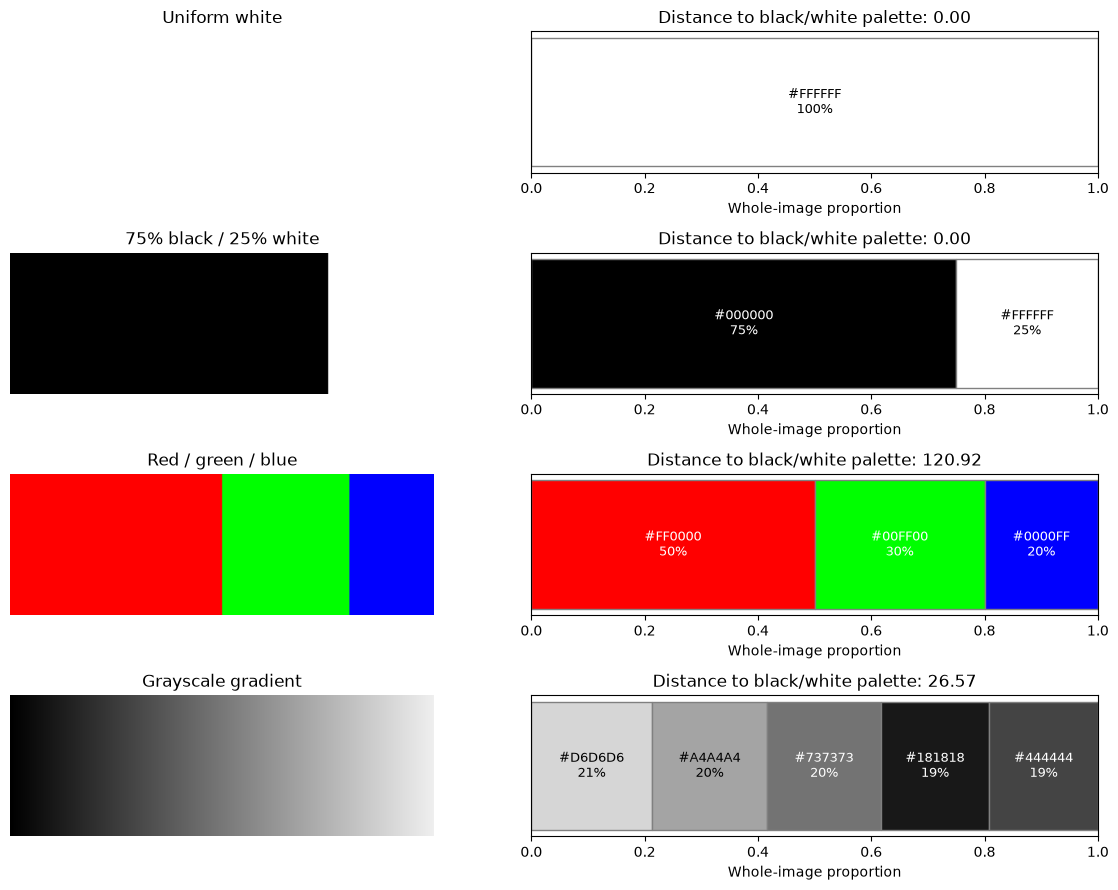

In [3]:
split = np.zeros((80, 240, 3), dtype=np.uint8)
split[:, 180:] = 255
stripes = np.zeros_like(split)
stripes[:, :120] = [255, 0, 0]
stripes[:, 120:192] = [0, 255, 0]
stripes[:, 192:] = [0, 0, 255]
ramp = np.tile(np.arange(240, dtype=np.uint8), (80, 1))
images = {
    "Uniform white": Image.new("RGB", (240, 80), "white"),
    "75% black / 25% white": Image.fromarray(split),
    "Red / green / blue": Image.fromarray(stripes),
    "Grayscale gradient": Image.fromarray(ramp).convert("RGB"),
}


def draw_palette(ax, colors):
    left = 0.0
    for color in colors:
        width = color["proportion"]
        ax.barh(0, width, left=left, color=color["hex"], edgecolor="gray")
        label = f"{color['hex']}\n{width:.0%}"
        text_color = "black" if np.mean(color["rgb"]) > 140 else "white"
        ax.text(
            left + width / 2,
            0,
            label,
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
        )
        left += width
    ax.set_xlim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel("Whole-image proportion")


results = {}
fig, axes = plt.subplots(len(images), 2, figsize=(12, 9))
for row, (name, image) in enumerate(images.items()):
    result = criterion.analyze(CVInput(image))
    results[name] = result
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(name)
    axes[row, 0].axis("off")
    draw_palette(axes[row, 1], result["measurements"]["dominant_colors"])
    axes[row, 1].set_title(
        f"Distance to black/white palette: {result['measurements']['palette_distance']:.2f}"
    )
fig.tight_layout()
plt.show()

## Read the result

`dominant_colors` contains RGB, hex, Lab and proportion for each cluster.
`method.parameters` records the configuration used. `available` means computable.
The simple split image illustrates a known distance: to black alone it would be
0.75 × 0 + 0.25 × 100 = 25. To a palette containing both black and white, it is zero.

In [4]:
print(json.dumps(results["75% black / 25% white"], indent=2, allow_nan=False))

{
  "schema_version": "1.0.0",
  "criterion_id": "color_palette_fit",
  "status": "available",
  "measurements": {
    "dominant_colors": [
      {
        "rgb": [
          0,
          0,
          0
        ],
        "hex": "#000000",
        "lab": [
          0.0,
          0.0,
          0.0
        ],
        "proportion": 0.75
      },
      {
        "rgb": [
          255,
          255,
          255
        ],
        "hex": "#FFFFFF",
        "lab": [
          100.0,
          0.0,
          0.0
        ],
        "proportion": 0.25
      }
    ],
    "palette_distance": 0.0
  },
  "method": {
    "id": "lab_kmeans_weighted_nearest_delta_e_76",
    "version": "1",
    "parameters": {
      "n_clusters": 5,
      "random_seed": 42,
      "max_sample_pixels": 50000,
      "brand_palette": [
        "#000000",
        "#FFFFFF"
      ]
    }
  },
  "units": {
    "dominant_colors": "RGB_0_255_hex_CIELAB_D65_proportion_0_1",
    "palette_distance": "delta_e_76"
  },
  "reas

## Compare palettes for the same image

The closest match can change when the configured palette changes. Multiple image
colors may match the same palette entry. This distance does not require every
palette color to appear, and it is not normalized to a 0–1 score.

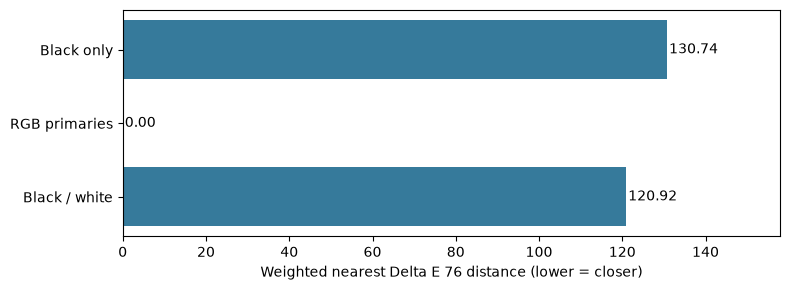

In [5]:
palettes = {
    "Black / white": ["#000000", "#FFFFFF"],
    "RGB primaries": ["#FF0000", "#00FF00", "#0000FF"],
    "Black only": ["#000000"],
}
data = CVInput(images["Red / green / blue"])
distances = {}
for name, colors in palettes.items():
    analyzer = ColorPaletteCriterion({"brand_palette": colors})
    distances[name] = analyzer.analyze(data)["measurements"]["palette_distance"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(list(distances), list(distances.values()), color="#367A9B")
ax.set_xlabel("Weighted nearest Delta E 76 distance (lower = closer)")
for row, value in enumerate(distances.values()):
    ax.text(value + 0.5, row, f"{value:.2f}", va="center")
ax.set_xlim(0, max(distances.values()) * 1.2 + 1)
fig.tight_layout()
plt.show()

## Change the number of representative colors

More clusters can represent a gradient more closely, but increase computation.
`max_sample_pixels=None` fits all pixels; a finite limit fits a reproducible sample
without resizing. Membership proportions still count all pixels. Sampling can miss
small regions. Fixed seeds support repeatability within a numerical environment.

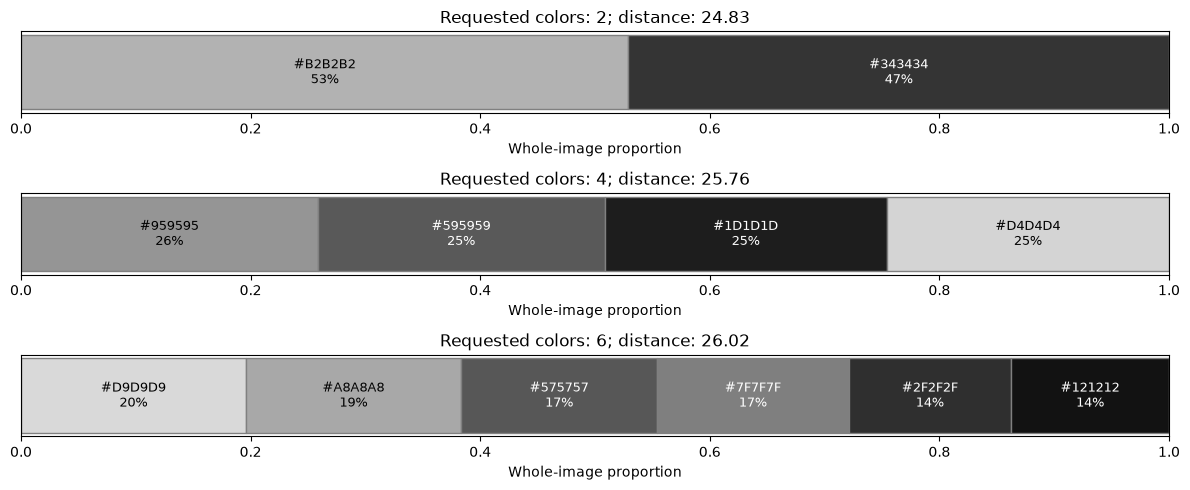

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 5))
for ax, count in zip(axes, (2, 4, 6), strict=True):
    analyzer = ColorPaletteCriterion(
        {
            "n_clusters": count,
            "random_seed": 42,
            "max_sample_pixels": 1000,
            "brand_palette": palette,
        }
    )
    result = analyzer.analyze(CVInput(images["Grayscale gradient"]))
    draw_palette(ax, result["measurements"]["dominant_colors"])
    ax.set_title(
        f"Requested colors: {count}; distance: {result['measurements']['palette_distance']:.2f}"
    )
fig.tight_layout()
plt.show()

## Extract colors before a brand palette is available

With no `brand_palette`, the criterion still returns dominant colors. The overall
status is `unavailable_needs_review` because palette distance cannot be computed.
A null distance is not a zero distance or a failing brand score.

In [7]:
result = ColorPaletteCriterion().analyze(CVInput(images["Red / green / blue"]))
print("Status:", result["status"])
print("Distance:", result["measurements"]["palette_distance"])
print("Reason:", result["reasons"])
print(
    "Extracted colors:",
    [color["hex"] for color in result["measurements"]["dominant_colors"]],
)

Status: unavailable_needs_review
Distance: None
Reason: ['No brand_palette configured; palette distance is unavailable.']
Extracted colors: ['#FF0000', '#00FF00', '#0000FF']


## Optional real photograph

Set the path below and replace the example palette with an approved brand palette.
Use the existing standardizer for EXIF orientation, color profiles and transparency.
Converting to RGB mode alone does not perform all of these operations.

In [8]:
photo_path = None  # Example: repo_root / "data" / "example.jpg"
if photo_path is not None:
    from brandlens.preprocessing.standardization import standardize_image

    with Image.open(photo_path) as original:
        image = standardize_image(original)
    try:
        display(image)
        result = criterion.analyze(CVInput(image))
        fig, ax = plt.subplots(figsize=(12, 2))
        draw_palette(ax, result["measurements"]["dominant_colors"])
        fig.tight_layout()
        plt.show()
        print(json.dumps(result, indent=2, allow_nan=False))
    finally:
        image.close()
else:
    print("Set photo_path to run the real-photo example.")

Set photo_path to run the real-photo example.
